# Stage 3, Track B v8 - Cetacean classifier retrained against prawn, tuna and Stage 2's own boxes

**Why this version exists.** The integrated end-to-end test (Stage 1 + 2 + Track A + Track B) showed Track B calling
81% of prawn frames and 85% of tuna frames "cetacean". Cause: v6 only ever saw two kinds of region - human-drawn cetacean
boxes, and random patches of plain water from the same photos. It learned "different from the water around it", which a
prawn plume or tuna boil also is. Its 5.1% false-alarm rate was measured on plain water only.

### What v8 changes
1. **Hard negatives.** Stage 1 + Stage 2 are run on development images of prawns, tuna and sea (Stage_02 training images and
   Val_data - the same folders the end-to-end test already treats as "development"). The box Stage 2 draws becomes a
   `not_cetacean` example. Test_data is never touched.
2. **Boxes drawn by Stage 2, for cetaceans too.** In the end-to-end test Track B scores Stage 2's box, not a human's. If only the
   negatives came from Stage 2, the model could learn "looks like a Stage 2 box = not cetacean". So Stage 2 is also run on
   cetacean photos from the TRAINING groups; where its box covers a labelled animal, that box is a `cetacean` example.
3. **Balanced by where the box came from.** Within each class, human boxes / water patches and Stage-2 boxes get equal total
   weight, so box origin carries no information about the label.
4. **Scored per kind of example**, not just overall. The feature set is chosen by the average of the per-kind recalls.

### What stays the same
- The cetacean photos, the duplicate grouping and the train / held-out split are exactly v6's (cells 1-7 are unchanged), so the held-out
  cetacean photos are the same ones as before. Cell 7 prints a check against v6's numbers.
- Same features, same feature settings, same logistic regression.

### What v8 cannot fix
- Stage 2 finding nothing on about 30% of cetacean frames (SegFormer has never been trained on cetaceans). Track B never sees those.
- Photos with an empty label file are NOT used as negatives: whether "empty" means "no animal" is still undecided.
- Stage 2 boxes on cetacean photos are only available where Stage 2 worked, so those positives are the easier cases.
- Only held-out photos give an honest number. Rows from the same photo group are never split across train and held-out.

### Run order
Run every cell from the top. Cells 7c to 7e load SegFormer and run it over roughly 1,500 images (30-60 minutes on CPU); results are
cached in `trackb_pipeline_boxes_cache.json`, so a re-run is quick. Cell 9b saves `stage3_output/track_b_model_v8.pkl`
(a different file name from v6 on purpose, so v6 is not overwritten).

The v6 photo galleries (its cells 12-24) are not included; they depended on every row coming from a cetacean photo.

In [1]:
# --- Cell 1: Config ---
from pathlib import Path
import random

random.seed(42)

CETACEAN_IMAGES_DIR = Path(r"C:\Users\bcura\AI PostGrad Project\Saqqara-Marine-Anomaly-Detection\Stage_03\Stage3_TrackB\train\images")        # UPDATE THIS - folder of .jpg/.png files
CETACEAN_ANNOTATIONS_DIR = Path(r"C:\Users\bcura\AI PostGrad Project\Saqqara-Marine-Anomaly-Detection\Stage_03\Stage3_TrackB\train\labels")  # UPDATE THIS - folder of matching .txt files
IMAGE_EXTS = {".jpg", ".jpeg", ".png"}

RING_PAD_FRAC = 0.5       # ring width around each box, as a fraction of the box's own size
N_NEGATIVES_PER_IMAGE = 2  # how many empty regions to sample per image as negative examples
N_EVAL_GROUPS_TARGET = 0.2 # roughly 20% of duplicate-groups held out for eval

# --- v6 additions ---
BAR_MEAN_THRESH = 10   # a column/row whose brightest-channel average is below this counts as a black letterbox bar
MIN_BAR_PX = 8         # ignore dark edges thinner than this (compression artefacts, not real bars)
BAR_MARGIN_PX = 2      # trim this many extra pixels inside a detected bar edge
BLACK_L_THRESH = 8     # pixels darker than this (LAB lightness, 0-255) are treated as padding and ignored
CV_FOLDS = 5           # cross-validation folds (built so no photo group is ever split across folds)


# --- v8 additions ---
ROOT = Path(r"C:\Users\bcura\AI PostGrad Project\Saqqara-Marine-Anomaly-Detection\Stage_03")

# Development images used as HARD NEGATIVES: (kind, folder, max images). These are the same folders the end-to-end test lists as
# development data, so its audit already keeps look-alikes of them out of Test_data. Do NOT add Test_data folders here.
HARD_NEGATIVE_SOURCES = [
    ("hard_prawn", ROOT.parent / "Stage_02" / "prawn_annotation_training" / "images" / "default", None),
    ("hard_tuna",  ROOT.parent / "Stage_02" / "tuna_annotation_training" / "images" / "default", 250),
    ("hard_tuna",  ROOT / "Val_data" / "TUNA", 250),
    ("hard_sea",   ROOT / "Val_data" / "SEA", 300),
]
CET_PIPELINE_MAX_IMAGES = 600      # cetacean TRAINING photos (one per photo group) to run through Stage 1 + 2 for positives
HARD_NEG_MASS = 0.5                # share of the not_cetacean weight carried by hard negatives (the rest: plain-water patches)
PIPELINE_POS_MASS = 0.5            # share of the cetacean weight carried by Stage-2-box positives (the rest: human boxes)
V6_HELD_OUT_FILES, V6_HELD_OUT_GROUPS = 1513, 591    # what v6 held out (printed by the integrated test), for the check in cell 7
PIPELINE_BOX_CACHE = Path("trackb_pipeline_boxes_cache.json")

# Where the trained Stage 1 / Stage 2 / Track A files are (searched for if not in the working folder; see cell 7b)
STAGE1_CONFIG_PATH = Path("stage1_final_config.json")
STAGE1_BUCKET_REF_PATH = Path("stage1_bucket_ref.pkl")
SEGFORMER_CHECKPOINT_PATH = Path("stage2_output/segformer_b0_epoch30.pt")
TRACK_A_BUNDLE_PATH = Path("stage3_output/track_a_model.pkl")      # only read for its settings, so Stage 2 runs exactly as in the test
ARTEFACT_OVERRIDES = {
    # "stage1_config": r"C:\...\stage1_final_config.json",
    # "stage1_bucket": r"C:\...\stage1_bucket_ref.pkl",
    # "segformer":     r"C:\...\segformer_b0_epoch30.pt",
    # "track_a":       r"C:\...\track_a_model.pkl",
}

print("Config set.")

Config set.


In [2]:
# --- Cell 2: Load every image + its YOLO annotation ---

def load_yolo_boxes(txt_path, img_w, img_h):
    """Returns a list of (class_id, x0, y0, x1, y1) in PIXEL coordinates."""
    boxes = []
    if not txt_path.exists():
        return boxes
    for line in txt_path.read_text().strip().splitlines():
        parts = line.split()
        if len(parts) < 5:
            continue
        cls_id, xc, yc, w, h = int(parts[0]), *map(float, parts[1:5])
        bw, bh = w * img_w, h * img_h
        x0, y0 = (xc * img_w) - bw / 2, (yc * img_h) - bh / 2
        boxes.append((cls_id, x0, y0, x0 + bw, y0 + bh))
    return boxes

from PIL import Image

image_paths = sorted(p for p in CETACEAN_IMAGES_DIR.rglob("*") if p.suffix.lower() in IMAGE_EXTS)
annotation_paths_by_stem = {p.stem: p for p in CETACEAN_ANNOTATIONS_DIR.rglob("*.txt")}
print(f"Found {len(annotation_paths_by_stem)} annotation files in {CETACEAN_ANNOTATIONS_DIR}")
print(f"Found {len(image_paths)} images")

records = []
n_empty = 0
for img_path in image_paths:
    txt_path = annotation_paths_by_stem.get(img_path.stem)
    if txt_path is None:
        n_empty += 1
        records.append({"path": img_path, "img_w": img_w, "img_h": img_h, "boxes": []})
        continue
    with Image.open(img_path) as im:
        img_w, img_h = im.size
    boxes = load_yolo_boxes(txt_path, img_w, img_h)
    if not boxes:
        n_empty += 1
    records.append({"path": img_path, "img_w": img_w, "img_h": img_h, "boxes": boxes})

print(f"Images with at least one box: {len(records) - n_empty}")
n_missing_file = sum(1 for r in records if r["path"].stem not in annotation_paths_by_stem)
print(f"Images with ZERO boxes: {n_empty} total "
      f"({n_missing_file} had no matching .txt file at all, "
      f"{n_empty - n_missing_file} had a .txt file that was empty)")

Found 7460 annotation files in C:\Users\bcura\AI PostGrad Project\Saqqara-Marine-Anomaly-Detection\Stage_03\Stage3_TrackB\train\labels
Found 7460 images
Images with at least one box: 5632
Images with ZERO boxes: 1828 total (0 had no matching .txt file at all, 1828 had a .txt file that was empty)


In [3]:
# --- Cell 3: Detect duplicate / rotated / flipped source photos ---
# Rotation and flipping preserve each box"s (width, height) exactly - only position changes.
# Two images sharing the same SET of box dimensions are almost certainly the same source photo.
# This is the safeguard from the 7-image sample finding: 2 of 7 were duplicates of each other.

def box_dims_fingerprint(record, decimals=3):
    # v6: width and height are sorted WITHIN each box, so a 90-degree rotation (which swaps width and
    # height) gives the same fingerprint. Before, only copies with identical (width, height) order matched.
    dims = sorted(
        tuple(sorted((round(x1 - x0, decimals), round(y1 - y0, decimals))))
        for _, x0, y0, x1, y1 in record["boxes"]
    )
    return tuple(dims)

groups = {}   # fingerprint -> list of record indices
for i, r in enumerate(records):
    if not r["boxes"]:
        continue   # unboxed images have no fingerprint to group by - handled separately
    fp = box_dims_fingerprint(r)
    groups.setdefault(fp, []).append(i)

dup_groups = {fp: idxs for fp, idxs in groups.items() if len(idxs) > 1}
n_in_dup_groups = sum(len(idxs) for idxs in dup_groups.values())

print(f"Distinct box-dimension fingerprints (boxed images only): {len(groups)}")
print(f"Fingerprints shared by more than one image (duplicate/rotated groups): {len(dup_groups)}")
print(f"Images involved in a duplicate group: {n_in_dup_groups} of {sum(1 for r in records if r["boxes"])}")

if dup_groups:
    print("\nExample duplicate groups found:")
    for fp, idxs in list(dup_groups.items())[:5]:
        names = [records[i]["path"].name for i in idxs]
        print(f"  {names}")

# Every image gets a group id - images not in any duplicate group are their own group of size 1
group_id_of = {}
next_group_id = 0
for fp, idxs in groups.items():
    for i in idxs:
        group_id_of[i] = next_group_id
    next_group_id += 1
for i, r in enumerate(records):
    if i not in group_id_of:
        group_id_of[i] = next_group_id
        next_group_id += 1

print(f"\nTotal distinct groups (this is the REAL sample size for splitting purposes): {next_group_id}")
print(f"(vs. {len(records)} raw image files - the gap is inflation from duplicates/rotations)")

Distinct box-dimension fingerprints (boxed images only): 1128
Fingerprints shared by more than one image (duplicate/rotated groups): 986
Images involved in a duplicate group: 5490 of 5632

Example duplicate groups found:
  ['1000_jpg.rf.946320ea54f81b9e9255f4cfe5b39852.jpg', '1000_jpg.rf.da16de0f39a5998f1844f43b45e62b73.jpg', '1400_jpg.rf.19701f2df77140c09ed7ccb9e55f3b54.jpg', '1400_jpg.rf.22f1354e044f250566ec4dcac7316b0d.jpg', '279_jpg.rf.101fc55ad7fce7c53cce654dc5142902.jpg', '3000_jpg.rf.1f6f0d340ee8983196c33c6998c9556b.jpg', '3000_jpg.rf.6da002c8d19bbce8ad264ef42347d7ac.jpg', '3800_jpg.rf.0c8ea43ab9787800cfdccb99958d87ab.jpg', '600_jpg.rf.16c2ddff6f2f92b0171e76ce2d61fb0c.jpg']
  ['1000_jpg.rf.9bec96836b3de2d8b3ec5ab7d854be2a.jpg', '3000_jpg.rf.1584776f956e46b43f30c91b8a84c8ee.jpg', '3800_jpg.rf.2416cb97f2974d6b3cde4d1c656e214c.jpg']
  ['1002_jpg.rf.36126b89ec4fa3b6c27c5a2ef7a8b784.jpg', '1402_jpg.rf.678f88f149ffc98721938a1685ca707c.jpg', '1402_jpg.rf.dcf3870bcb6acd19cc99e86b3c4612a

In [4]:
# --- Cell 4: Feature extraction - box shape + brightness/colour vs. surrounding water ---
# v6: works inside the picture area only (black letterbox bars excluded) and takes a pre-computed LAB image.

import numpy as np
import cv2


def detect_content_box(img_rgb, bar_mean_thresh=BAR_MEAN_THRESH, min_bar_px=MIN_BAR_PX, margin=BAR_MARGIN_PX):
    """Finds the picture area inside black letterbox bars.
    Returns (x0, y0, x1, y1, has_bars). Bars are trimmed from the outside edges inward only."""
    H, W = img_rgb.shape[:2]
    # profiles from every 8th row / column: far cheaper, and still exact to the pixel at the bar edges
    col_profile = img_rgb[::8].max(axis=2).mean(axis=0)       # one value per column
    row_profile = img_rgb[:, ::8].max(axis=2).mean(axis=1)    # one value per row

    def trim(profile, n):
        good = np.flatnonzero(profile >= bar_mean_thresh)
        if good.size == 0:
            return 0, n
        lo, hi = int(good[0]), int(good[-1]) + 1
        lo = lo + margin if lo >= min_bar_px else 0
        hi = hi - margin if (n - hi) >= min_bar_px else n
        return lo, hi

    x0, x1 = trim(col_profile, W)
    y0, y1 = trim(row_profile, H)
    if (x1 - x0) < 0.3 * W or (y1 - y0) < 0.3 * H:   # implausible - fall back to the full canvas
        return 0, 0, W, H, False
    return x0, y0, x1, y1, (x0, y0, x1, y1) != (0, 0, W, H)


def extract_box_features(img_rgb, box, content=None, lab=None, ring_pad_frac=RING_PAD_FRAC):
    """box = (x0, y0, x1, y1) in pixel coords. content = (x0, y0, x1, y1) picture area (default: whole image).
    Returns a feature dict, or None if the box is degenerate, mostly padding, or has no usable ring."""
    H, W = img_rgb.shape[:2]
    cx0, cy0, cx1, cy1 = content if content is not None else (0, 0, W, H)
    if lab is None:
        lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB).astype(np.float32)

    x0, y0, x1, y1 = [int(round(v)) for v in box]
    x0, y0 = max(cx0, x0), max(cy0, y0)
    x1, y1 = min(cx1, x1), min(cy1, y1)
    bw, bh = x1 - x0, y1 - y0
    if bw < 4 or bh < 4:
        return None

    pad_x, pad_y = int(bw * ring_pad_frac), int(bh * ring_pad_frac)
    rx0, ry0 = max(cx0, x0 - pad_x), max(cy0, y0 - pad_y)
    rx1, ry1 = min(cx1, x1 + pad_x), min(cy1, y1 + pad_y)

    region = lab[ry0:ry1, rx0:rx1]
    ring_mask = np.ones(region.shape[:2], dtype=bool)
    ring_mask[y0 - ry0:y1 - ry0, x0 - rx0:x1 - rx0] = False
    ring = region[ring_mask]
    inside = lab[y0:y1, x0:x1].reshape(-1, 3)

    # near-black pixels are padding (letterbox leftovers, rotation corners), not water
    ring = ring[ring[:, 0] > BLACK_L_THRESH]
    inside = inside[inside[:, 0] > BLACK_L_THRESH]
    if ring.shape[0] < 20 or inside.shape[0] < 0.5 * bw * bh:
        return None

    aspect_ratio = max(bw, bh) / max(1, min(bw, bh))
    relative_area = (bw * bh) / ((cx1 - cx0) * (cy1 - cy0))
    in_L, in_a, in_b = inside[:, 0], inside[:, 1], inside[:, 2]
    r_L, r_a, r_b = ring[:, 0], ring[:, 1], ring[:, 2]

    return {
        "aspect_ratio": aspect_ratio,
        "relative_area": relative_area,
        "in_L": float(in_L.mean()), "ring_L": float(r_L.mean()),
        "contrast_L": float(in_L.mean() - r_L.mean()),
        "in_a": float(in_a.mean()), "ring_a": float(r_a.mean()),
        "in_b": float(in_b.mean()), "ring_b": float(r_b.mean()),
        "in_L_std": float(in_L.std()),
    }


FEATURE_COLS_ALL = ["aspect_ratio", "relative_area", "in_L", "ring_L", "contrast_L",
                     "in_a", "ring_a", "in_b", "ring_b", "in_L_std"]
SHAPE_FEATURES = ["aspect_ratio", "relative_area"]
SIGNATURE_FEATURES = ["contrast_L", "in_a", "ring_a", "in_b", "ring_b", "in_L_std"]

print("Feature function ready.")

Feature function ready.


In [5]:
# --- Cell 5: Sample negative (non-cetacean) regions from the SAME photos ---
# v6 changes:
#  - patches are drawn only from inside the picture area (never from black letterbox bars)
#  - each patch copies one REAL (width, height) pair, so shapes match the positives
#  - images with NO annotated box draw sizes from the dataset-wide real box sizes
#    (before, they all got one fixed 10% x 10% patch, a size shortcut for the classifier)

def boxes_overlap(a, b):
    ax0, ay0, ax1, ay1 = a
    bx0, by0, bx1, by1 = b
    return not (ax1 <= bx0 or bx1 <= ax0 or ay1 <= by0 or by1 <= ay0)


# real box sizes as fractions of the full canvas, across the whole dataset
GLOBAL_REL_SIZES = []
for rec in records:
    for _, bx0, by0, bx1, by1 in rec["boxes"]:
        GLOBAL_REL_SIZES.append(((bx1 - bx0) / rec["img_w"], (by1 - by0) / rec["img_h"]))
if not GLOBAL_REL_SIZES:
    GLOBAL_REL_SIZES = [(0.1, 0.1)]
print(f"Real box sizes collected for empty-image negatives: {len(GLOBAL_REL_SIZES)}")


def sample_negative_boxes(record, n_needed, content, max_tries=60):
    """Returns (list of boxes, from_empty_image)."""
    W, H = record["img_w"], record["img_h"]
    cx0, cy0, cx1, cy1 = content
    cw, ch = cx1 - cx0, cy1 - cy0
    real_boxes = [(x0, y0, x1, y1) for _, x0, y0, x1, y1 in record["boxes"]]

    if real_boxes:
        size_pool = [(x1 - x0, y1 - y0) for x0, y0, x1, y1 in real_boxes]
        from_empty = False
    else:
        size_pool = [(rw * W, rh * H) for rw, rh in GLOBAL_REL_SIZES]
        from_empty = True

    out = []
    for _ in range(n_needed):
        for _try in range(max_tries):
            bw, bh = random.choice(size_pool)
            if bw >= cw or bh >= ch:
                continue
            x0 = random.uniform(cx0, cx1 - bw)
            y0 = random.uniform(cy0, cy1 - bh)
            cand = (x0, y0, x0 + bw, y0 + bh)
            if not any(boxes_overlap(cand, rb) for rb in real_boxes):
                out.append(cand)
                break
    return out, from_empty

print("Negative sampling ready.")

Real box sizes collected for empty-image negatives: 19850
Negative sampling ready.


In [6]:
# --- Cell 6: Extract features for every positive and negative example ---
# v6: detects letterbox bars per image, converts to LAB once per image, restricts everything to the picture area.

rows = []
n_letterboxed = 0
n_real_boxes = sum(len(r["boxes"]) for r in records)
n_dropped_pos = 0
n_dropped_neg = 0
n_neg_from_empty = 0
empty_neg_sizes = set()

for i, r in enumerate(records):
    try:
        img = np.array(Image.open(r["path"]).convert("RGB"))
    except Exception as e:
        print("Could not open", r["path"].name, e)
        continue

    cx0, cy0, cx1, cy1, has_bars = detect_content_box(img)
    content = (cx0, cy0, cx1, cy1)
    r["content"] = content
    n_letterboxed += int(has_bars)
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB).astype(np.float32)

    for _, x0, y0, x1, y1 in r["boxes"]:
        feats = extract_box_features(img, (x0, y0, x1, y1), content=content, lab=lab)
        if feats is None:
            n_dropped_pos += 1
            continue
        feats.update(label="cetacean", group_id=group_id_of[i], filename=r["path"].name,
                      box=(x0, y0, x1, y1), source_empty=False)
        rows.append(feats)

    neg_boxes, from_empty = sample_negative_boxes(r, N_NEGATIVES_PER_IMAGE, content)
    for neg in neg_boxes:
        feats = extract_box_features(img, neg, content=content, lab=lab)
        if feats is None:
            n_dropped_neg += 1
            continue
        feats.update(label="not_cetacean", group_id=group_id_of[i], filename=r["path"].name,
                      box=neg, source_empty=from_empty)
        rows.append(feats)
        if from_empty:
            n_neg_from_empty += 1
            empty_neg_sizes.add((round(neg[2] - neg[0]), round(neg[3] - neg[1])))

n_pos = sum(1 for row in rows if row["label"] == "cetacean")
n_neg = sum(1 for row in rows if row["label"] == "not_cetacean")
n_groups_in_rows = len(set(row["group_id"] for row in rows))
print(f"Extracted {len(rows)} rows total: {n_pos} cetacean, {n_neg} not_cetacean")
print(f"From {n_groups_in_rows} distinct source-photo groups")

print("\nv6 checks:")
print(f"  images with black letterbox bars: {n_letterboxed} of {len(records)} ({n_letterboxed / max(1, len(records)):.1%})")
print(f"  real boxes dropped (mostly padding / no usable ring): {n_dropped_pos} of {n_real_boxes}")
print(f"  negatives dropped: {n_dropped_neg}")
print(f"  negatives from images with no annotated box: {n_neg_from_empty}, "
      f"using {len(empty_neg_sizes)} distinct patch sizes (was: one fixed size per resolution)")
n_dark_rows = sum(1 for row in rows if row["in_L"] < 15)
print(f"  rows whose inside brightness is near-black (should be ~0): {n_dark_rows}")

if len(rows) == 0:
    n_recs = len(records)
    n_recs_with_boxes = sum(1 for r in records if r["boxes"])
    raise RuntimeError(
        "Extracted ZERO rows - stop here, do not continue to later cells.\n"
        f"  CETACEAN_IMAGES_DIR = {CETACEAN_IMAGES_DIR}\n"
        f"  records loaded = {n_recs}\n"
        f"  records with boxes = {n_recs_with_boxes}\n"
        "If records=0: check CETACEAN_IMAGES_DIR / CETACEAN_ANNOTATIONS_DIR in cell 1 are correct.\n"
        "If records>0 but rows=0: extract_box_features is rejecting every box - check image files "
        "actually match the annotation filenames, and that images are not corrupt/unreadable."
    )

Extracted 34765 rows total: 19847 cetacean, 14918 not_cetacean
From 2956 distinct source-photo groups

v6 checks:
  images with black letterbox bars: 3114 of 7460 (41.7%)
  real boxes dropped (mostly padding / no usable ring): 3 of 19850
  negatives dropped: 2
  negatives from images with no annotated box: 3655, using 1994 distinct patch sizes (was: one fixed size per resolution)
  rows whose inside brightness is near-black (should be ~0): 1


In [7]:
# --- Cell 7: Train/eval split BY GROUP, never by individual file ---
# This is the safeguard: a duplicate or rotated copy of a training image can never end up in eval.

# v8: every row is tagged with where it came from. (Cells 2-6 are unchanged, so the random state here is the same as in v6 and the
# split below picks the same held-out photo groups as v6 did.)
for row in rows:
    row["kind"] = "cet_annotation" if row["label"] == "cetacean" else "water_patch"
    row["path"] = str(CETACEAN_IMAGES_DIR / row["filename"])

all_group_ids = sorted(set(row["group_id"] for row in rows))
random.shuffle(all_group_ids)
n_eval_groups = max(1, int(len(all_group_ids) * N_EVAL_GROUPS_TARGET))
eval_group_ids = set(all_group_ids[:n_eval_groups])
train_group_ids = set(all_group_ids[n_eval_groups:])

train_rows = [row for row in rows if row["group_id"] in train_group_ids]
eval_rows = [row for row in rows if row["group_id"] in eval_group_ids]

print(f"Groups: {len(train_group_ids)} train, {len(eval_group_ids)} eval")
print(f"Rows:   {len(train_rows)} train "
      f"(cetacean={sum(r["label"]=="cetacean" for r in train_rows)}, "
      f"not_cetacean={sum(r["label"]=="not_cetacean" for r in train_rows)})")
print(f"        {len(eval_rows)} eval  "
      f"(cetacean={sum(r["label"]=="cetacean" for r in eval_rows)}, "
      f"not_cetacean={sum(r["label"]=="not_cetacean" for r in eval_rows)})")

overlap_check = train_group_ids & eval_group_ids
assert not overlap_check, f"BUG: {len(overlap_check)} groups appear in both train and eval"
print("\nConfirmed: zero groups appear in both train and eval.")
_files = len(set(r["filename"] for r in eval_rows)); _groups = len(set(r["group_id"] for r in eval_rows))
if (_files, _groups) == (V6_HELD_OUT_FILES, V6_HELD_OUT_GROUPS):
    print(f"\nCheck passed: held-out photos = {_files} files in {_groups} groups, identical in size to v6's.")
else:
    print(f"\nNOTE: held-out photos = {_files} files in {_groups} groups; v6 held out {V6_HELD_OUT_FILES} files in {V6_HELD_OUT_GROUPS} groups. "
          "The split differs from v6 (different dataset or cells run out of order). That is allowed - the saved file lists exactly what was held out - "
          "but then do not compare these numbers with v6's.")

Groups: 2365 train, 591 eval
Rows:   27674 train (cetacean=15782, not_cetacean=11892)
        7091 eval  (cetacean=4065, not_cetacean=3026)

Confirmed: zero groups appear in both train and eval.

Check passed: held-out photos = 1513 files in 591 groups, identical in size to v6's.


In [8]:
# --- Cell 7b: Load Stage 1 / Stage 2 exactly as the end-to-end test does ---
# The pipeline settings are READ FROM the Track A file, so Stage 2 here cannot drift from what the test uses.
import os, json, time, pickle, datetime
import torch
import torch.nn.functional as F
from transformers import SegformerForSemanticSegmentation
from skimage.segmentation import slic
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern
from scipy import ndimage

print("This notebook is running from:", Path.cwd())
SEARCH_ROOTS = []
for _r in (Path.cwd(), ROOT.parent, ROOT):
    if _r.exists() and _r.resolve() not in [s.resolve() for s in SEARCH_ROOTS]:
        SEARCH_ROOTS.append(_r)

def find_artefact(key, rel_path, made_by):
    """override -> the relative path as written -> search the project folders (newest first)."""
    if key in ARTEFACT_OVERRIDES:
        p = Path(ARTEFACT_OVERRIDES[key])
        if not p.exists():
            raise FileNotFoundError(f"ARTEFACT_OVERRIDES['{key}'] points to a file that does not exist: {p}")
        return p, [p]
    if Path(rel_path).exists():
        return Path(rel_path), [Path(rel_path)]
    hits = {}
    for root in SEARCH_ROOTS:
        for dirpath, dirnames, filenames in os.walk(root):
            dirnames[:] = [d for d in dirnames if d not in (".git", "__pycache__", ".ipynb_checkpoints", "node_modules")]
            if rel_path.name in filenames:
                full = Path(dirpath) / rel_path.name
                hits[str(full.resolve())] = full
            if len(filenames) > 300:
                dirnames[:] = []
    cands = sorted(hits.values(), key=lambda p: p.stat().st_mtime, reverse=True)
    if not cands:
        raise FileNotFoundError(f"Could not find '{rel_path.name}' under {[str(r) for r in SEARCH_ROOTS]}.\n"
                                f"  It is created by: {made_by}.\n  Run that notebook first, or set ARTEFACT_OVERRIDES['{key}'] to the full path.")
    return cands[0], cands

_a_path, _a_c = find_artefact("track_a", TRACK_A_BUNDLE_PATH, "Stage_03_TrackA_v4_with_images_v3 (save cell)")
with open(_a_path, "rb") as f:
    _track_a = pickle.load(f)
_bs = _track_a["settings"]
_cfg_path, _cfg_c = find_artefact("stage1_config", STAGE1_CONFIG_PATH, "the Stage 1 notebook")
for _c in _cfg_c:                                    # several copies: take the one Track A was trained with
    with open(_c) as _f:
        if json.load(_f) == _track_a["stage1_config"]:
            _cfg_path = _c
            break
_bucket_path, _ = find_artefact("stage1_bucket", STAGE1_BUCKET_REF_PATH, "the Stage 1 notebook")
_seg_path, _seg_c = find_artefact("segformer", SEGFORMER_CHECKPOINT_PATH, "Stage_02_Pipeline_FINAL (training cell)")
print("Trained files being used:")
for k, p in (("track_a", _a_path), ("stage1_config", _cfg_path), ("stage1_bucket", _bucket_path), ("segformer", _seg_path)):
    print(f"  {k:<14} {p}   (saved {datetime.datetime.fromtimestamp(Path(p).stat().st_mtime):%Y-%m-%d %H:%M})")
if len(_seg_c) > 1:
    print(f"  ({len(_seg_c)} SegFormer copies found; using the newest.)")
with open(_cfg_path) as f:
    stage1_config = json.load(f)
with open(_bucket_path, "rb") as f:
    stage1_bucket_ref = pickle.load(f)
SEGFORMER_CHECKPOINT_PATH = _seg_path

STAGE2_PROB_THRESHOLD = _bs["prob"]
STAGE2_MIN_MASK_PIXELS = _bs["min_px"]
STAGE1_DILATION_ITERS = _bs["dilation"]
CROP_PADDING_PX = _bs["crop_pad"]
STAGE2_ROUTE = "whole_frame"
STAGE2_WHOLE_FRAME_PROB = 0.35
STAGE2_KEEP_LARGEST_BLOB = True
assert abs(STAGE2_WHOLE_FRAME_PROB - STAGE2_PROB_THRESHOLD) < 1e-9, "Stage 2 cut-off differs from the one Track A was trained with"
IMG_SIZE = tuple(stage1_config["img_size"])
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Stage 2: whole frame, cut-off {STAGE2_WHOLE_FRAME_PROB}, min mask {STAGE2_MIN_MASK_PIXELS} px, largest blob only.  Device: {device}")

This notebook is running from: C:\Users\bcura\AI PostGrad Project\Saqqara-Marine-Anomaly-Detection\Stage_03\Stage3_TrackB
Trained files being used:
  track_a        C:\Users\bcura\AI PostGrad Project\Saqqara-Marine-Anomaly-Detection\Combined Pipeline\track_a_model.pkl   (saved 2026-09-30 14:21)
  stage1_config  C:\Users\bcura\AI PostGrad Project\Saqqara-Marine-Anomaly-Detection\Combined Pipeline\stage1_final_config.json   (saved 2026-09-22 17:53)
  stage1_bucket  C:\Users\bcura\AI PostGrad Project\Saqqara-Marine-Anomaly-Detection\Combined Pipeline\stage1_bucket_ref.pkl   (saved 2026-09-22 17:53)
  segformer      C:\Users\bcura\AI PostGrad Project\Saqqara-Marine-Anomaly-Detection\Combined Pipeline\segformer_b0_epoch30.pt   (saved 2026-10-09 20:50)
  (3 SegFormer copies found; using the newest.)
Stage 2: whole frame, cut-off 0.35, min mask 80 px, largest blob only.  Device: cpu


In [9]:
# --- Cell 2: Load SegFormer-B0 with the best checkpoint ---

model = SegformerForSemanticSegmentation.from_pretrained(
    "nvidia/segformer-b0-finetuned-ade-512-512", num_labels=2,
    id2label={0: "background", 1: "anomaly"}, label2id={"background": 0, "anomaly": 1},
    ignore_mismatched_sizes=True,
)
model.load_state_dict(torch.load(SEGFORMER_CHECKPOINT_PATH, map_location=device))
model.to(device)
model.eval()
print(f"Loaded checkpoint: {SEGFORMER_CHECKPOINT_PATH}")

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `150`.


Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/segformer-b0-finetuned-ade-512-512
Key                           | Status   |                                                                                                     
------------------------------+----------+-----------------------------------------------------------------------------------------------------
decode_head.classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150, 256, 1, 1]) vs model:torch.Size([2, 256, 1, 1])
decode_head.classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150]) vs model:torch.Size([2])                      

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Loaded checkpoint: C:\Users\bcura\AI PostGrad Project\Saqqara-Marine-Anomaly-Detection\Combined Pipeline\segformer_b0_epoch30.pt


In [10]:
# --- Cell 3: Ported Stage 1 detector (texture rule OR local-brightness rule) ---

S1_N_SEGMENTS = stage1_config["n_segments"]
S1_COMPACTNESS = stage1_config["compactness"]
S1_GLCM_LEVELS = stage1_config["glcm_levels"]
S1_Z_THRESH = stage1_config["z_thresh"]
S1_GLINT_THRESH = stage1_config["glint_thresh"]
S1_MIN_COMPONENT_AREA_PX = stage1_config["min_component_area_px"]
S1_MIN_FEATURES_FLAGGED = stage1_config["min_features_flagged"]
S1_BUCKET_EDGES = np.array(stage1_config["bucket_edges"])
S1_LOCAL_Z_THRESH = stage1_config.get("local_z_thresh", 999)
S1_MIN_AREA_LOCAL = stage1_config.get("min_area_local", 999999999)
FEATURE_KEYS = ["contrast_L", "homogeneity_L", "energy_L", "contrast_a", "lbp_var"]

def suppress_glint(img_bgr, thresh=S1_GLINT_THRESH, dilate_iter=2):
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    L = lab[:, :, 0]
    glint_mask = (L > thresh).astype(np.uint8)
    kernel = np.ones((5, 5), np.uint8)
    glint_mask = cv2.dilate(glint_mask, kernel, iterations=dilate_iter)
    return cv2.morphologyEx(glint_mask, cv2.MORPH_CLOSE, kernel)

def preprocess_image_s1(path, glint_thresh=S1_GLINT_THRESH):
    img_bgr = cv2.resize(cv2.imread(str(path)), IMG_SIZE)
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    glint_mask = suppress_glint(img_bgr, glint_thresh)
    rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    return lab, glint_mask, rgb

def quantize_s1(patch, levels=S1_GLCM_LEVELS):
    return (patch.astype(np.float32) / 256 * levels).astype(np.uint8)

def glcm_props_s1(patch_q, levels=S1_GLCM_LEVELS):
    glcm = graycomatrix(patch_q, distances=[1], angles=[0], levels=levels, symmetric=True, normed=True)
    return (float(graycoprops(glcm, 'contrast')[0, 0]), float(graycoprops(glcm, 'homogeneity')[0, 0]), float(graycoprops(glcm, 'energy')[0, 0]))

def extract_superpixel_features_s1(img_lab, glint_mask, n_segments=S1_N_SEGMENTS, compactness=S1_COMPACTNESS):
    L_channel, a_channel = img_lab[:, :, 0], img_lab[:, :, 1]
    segments = slic(img_lab, n_segments=n_segments, compactness=compactness, start_label=1)
    objects = ndimage.find_objects(segments)
    features = []
    for seg_id, bbox in enumerate(objects, start=1):
        if bbox is None:
            continue
        y_slice, x_slice = bbox
        local_mask = segments[y_slice, x_slice] == seg_id
        if glint_mask[y_slice, x_slice][local_mask].mean() > 0.5:
            continue
        patch_L, patch_a = L_channel[y_slice, x_slice], a_channel[y_slice, x_slice]
        if patch_L.shape[0] < 2 or patch_L.shape[1] < 2:
            continue
        contrast_L, homogeneity_L, energy_L = glcm_props_s1(quantize_s1(patch_L))
        contrast_a, _, _ = glcm_props_s1(quantize_s1(patch_a))
        lbp_var = float(np.var(local_binary_pattern(patch_L, P=8, R=1, method='uniform')))
        features.append({"seg_id": int(seg_id), "contrast_L": contrast_L, "homogeneity_L": homogeneity_L,
                          "energy_L": energy_L, "contrast_a": contrast_a, "lbp_var": lbp_var, "mean_L": float(patch_L.mean())})
    return segments, features

def image_sea_state_score(img_lab, glint_mask):
    L = img_lab[:, :, 0]
    valid = glint_mask == 0
    return float(np.mean(L[valid] if valid.any() else L))

def assign_bucket_from_score(score, edges=S1_BUCKET_EDGES):
    return int(np.searchsorted(edges, score))

def score_region_deviation_s1(feat, baseline_ref, z_thresh, min_features_flagged):
    z_scores = {k: abs(feat[k] - baseline_ref[k][0]) / (baseline_ref[k][1] + 1e-6) for k in FEATURE_KEYS}
    return sum(1 for z in z_scores.values() if z > z_thresh) >= min_features_flagged

def _region_with_bbox(flagged_mask, min_area, dilation_iters=STAGE1_DILATION_ITERS):
    if dilation_iters > 0:
        flagged_mask = ndimage.binary_dilation(flagged_mask, iterations=dilation_iters)
    labeled, n_components = ndimage.label(flagged_mask)
    if n_components == 0:
        return False, 0, None
    sizes = ndimage.sum(flagged_mask, labeled, range(1, n_components + 1))
    biggest_label = int(np.argmax(sizes)) + 1
    max_component = float(sizes[biggest_label - 1])
    is_detected = max_component >= min_area
    bbox = None
    if is_detected:
        y_slice, x_slice = ndimage.find_objects(labeled)[biggest_label - 1]
        bbox = (x_slice.start, y_slice.start, x_slice.stop, y_slice.stop)
    return is_detected, max_component, bbox

def texture_rule_with_bbox(segments, feats, baseline_ref, z_thresh=S1_Z_THRESH, min_area=S1_MIN_COMPONENT_AREA_PX, min_features_flagged=S1_MIN_FEATURES_FLAGGED):
    flagged_ids = {f["seg_id"] for f in feats if score_region_deviation_s1(f, baseline_ref, z_thresh, min_features_flagged)}
    if not flagged_ids:
        return False, 0, None
    return _region_with_bbox(np.isin(segments, list(flagged_ids)), min_area)

def local_brightness_rule_with_bbox(feats, segments, local_z_thresh=S1_LOCAL_Z_THRESH, min_area_local=S1_MIN_AREA_LOCAL):
    if not feats:
        return False, 0, None
    mean_Ls = np.array([f["mean_L"] for f in feats])
    img_mean, img_std = mean_Ls.mean(), mean_Ls.std()
    flagged_ids = {f["seg_id"] for f in feats if abs(f["mean_L"] - img_mean) / (img_std + 1e-6) > local_z_thresh}
    if not flagged_ids:
        return False, 0, None
    return _region_with_bbox(np.isin(segments, list(flagged_ids)), min_area_local)

def get_flagging_result_with_bbox(segments, feats, baseline_ref):
    tex_detected, tex_area, tex_bbox = texture_rule_with_bbox(segments, feats, baseline_ref)
    local_detected, local_area, local_bbox = local_brightness_rule_with_bbox(feats, segments)
    if not tex_detected and not local_detected:
        return False, 0, None
    if tex_detected and local_detected:
        return (True, tex_area, tex_bbox) if tex_area >= local_area else (True, local_area, local_bbox)
    return (True, tex_area, tex_bbox) if tex_detected else (True, local_area, local_bbox)

print("Stage 1 detector ported and ready.")

Stage 1 detector ported and ready.


In [11]:
# --- Cell 4: Connected pipeline (Stage 1 -> Stage 2 on the WHOLE frame -> crop for Track A) ---
#
# What changed from the old version:
#   OLD: Stage 1's box (+20 px) was cut out and resized to 512x512 BEFORE SegFormer saw it. If Stage 1's box missed
#        the anomaly (the green box in the gallery), the anomaly was physically absent from Stage 2's input.
#   NEW: SegFormer sees the whole frame, so a misplaced Stage 1 box can no longer hide the object. The crop is made
#        AFTER Stage 2, around the mask, so Track A still receives the kind of input it was trained on.
#
# Result keys (unchanged names, so the later cells keep working):
#   bbox         crop region in 512x512 frame coordinates (what Track A's features use)
#   s1_bbox      Stage 1's own padded box, kept so the gallery can show where Stage 1 pointed
#   crop         float32 0-1, 512x512, the image Track A measures
#   stage2_mask  0/1, 512x512, in CROP space (lines up with `crop`)

def _segformer_probs(rgb_u8):
    """uint8 RGB image of any size -> anomaly probability at IMG_SIZE (rows = IMG_SIZE[1], cols = IMG_SIZE[0])."""
    arr = np.array(Image.fromarray(rgb_u8).resize(IMG_SIZE, Image.BILINEAR), dtype=np.float32) / 255.0
    arr = (arr - IMAGENET_MEAN) / IMAGENET_STD
    pixel_values = torch.from_numpy(arr.transpose(2, 0, 1)).unsqueeze(0).to(device)
    with torch.no_grad():
        logits = model(pixel_values=pixel_values).logits
        logits = F.interpolate(logits, size=(IMG_SIZE[1], IMG_SIZE[0]), mode="bilinear", align_corners=False)
        return F.softmax(logits, dim=1)[0, 1].cpu().numpy()

def _pad_box(box, pad, W, H):
    x0, y0, x1, y1 = box
    return max(0, x0 - pad), max(0, y0 - pad), min(W, x1 + pad), min(H, y1 + pad)

def _boxes_overlap(a, b):
    return min(a[2], b[2]) > max(a[0], b[0]) and min(a[3], b[3]) > max(a[1], b[1])

def _largest_blob(mask):
    labeled, n = ndimage.label(mask)
    if n <= 1:
        return mask
    sizes = ndimage.sum(mask, labeled, range(1, n + 1))
    return (labeled == (int(np.argmax(sizes)) + 1)).astype(mask.dtype)

def run_connected_pipeline(path, bucket_ref=stage1_bucket_ref, route=None):
    route = route or STAGE2_ROUTE
    lab, glint_mask, rgb = preprocess_image_s1(path)
    segments, feats = extract_superpixel_features_s1(lab, glint_mask)
    bucket = assign_bucket_from_score(image_sea_state_score(lab, glint_mask))
    is_detected, max_component, bbox = get_flagging_result_with_bbox(segments, feats, bucket_ref[bucket])

    result = {"path": str(path), "rgb": rgb, "is_detected": is_detected,
              "bbox": None, "s1_bbox": None, "crop": None, "stage2_mask": None, "n_flagged_px_stage2": 0,
              "stage2_raw_px": 0, "stage2_max_prob": None, "route": route}
    if not (is_detected and bbox is not None):
        return result

    H, W = rgb.shape[:2]
    s1_box = _pad_box(bbox, CROP_PADDING_PX, W, H)
    result["s1_bbox"] = s1_box

    # ---------------- OLD route: Stage 2 only sees Stage 1's padded box ----------------
    if route == "crop":
        x0p, y0p, x1p, y1p = s1_box
        crop = rgb[y0p:y1p, x0p:x1p]
        result["bbox"] = s1_box
        if crop.size == 0:
            return result
        crop_arr = np.array(Image.fromarray(crop).resize(IMG_SIZE, Image.BILINEAR), dtype=np.float32) / 255.0
        probs = _segformer_probs(crop)
        pred = (probs > STAGE2_PROB_THRESHOLD).astype(np.uint8)
        result["stage2_raw_px"] = int(pred.sum())
        result["stage2_max_prob"] = float(probs.max())
        if pred.sum() < STAGE2_MIN_MASK_PIXELS:
            pred = np.zeros_like(pred)
        result["crop"], result["stage2_mask"], result["n_flagged_px_stage2"] = crop_arr, pred, int(pred.sum())
        return result

    # ---------------- NEW route: Stage 2 sees the whole frame ----------------
    probs = _segformer_probs(rgb)                       # rgb is already IMG_SIZE, so this is frame space
    pred = (probs > STAGE2_WHOLE_FRAME_PROB).astype(np.uint8)
    result["stage2_raw_px"] = int(pred.sum())            # pixels above threshold anywhere in the frame
    result["stage2_max_prob"] = float(probs.max())
    if STAGE2_KEEP_LARGEST_BLOB and pred.any():
        pred = _largest_blob(pred)
    if pred.sum() < STAGE2_MIN_MASK_PIXELS:
        pred = np.zeros_like(pred)

    if pred.sum() == 0:
        # Nothing found. Keep the whole frame as "crop" so the gallery shows what Stage 2 was looking at.
        result["bbox"] = s1_box
        result["crop"] = rgb.astype(np.float32) / 255.0
        result["stage2_mask"] = np.zeros((IMG_SIZE[1], IMG_SIZE[0]), np.uint8)
        return result

    # Crop for Track A: around the mask. Where Stage 2 agrees with Stage 1's box (they overlap) the crop is the union
    # of the two, which is what Track A was trained on; where they disagree, Stage 1's box was in the wrong place and
    # only the mask's own box is used.
    ys, xs = np.where(pred > 0)
    mask_box = _pad_box((int(xs.min()), int(ys.min()), int(xs.max()) + 1, int(ys.max()) + 1), CROP_PADDING_PX, W, H)
    if _boxes_overlap(mask_box, s1_box):
        crop_box = (min(mask_box[0], s1_box[0]), min(mask_box[1], s1_box[1]),
                    max(mask_box[2], s1_box[2]), max(mask_box[3], s1_box[3]))
    else:
        crop_box = mask_box
    x0, y0, x1, y1 = crop_box
    crop_arr = np.array(Image.fromarray(rgb[y0:y1, x0:x1]).resize(IMG_SIZE, Image.BILINEAR), dtype=np.float32) / 255.0
    mask_crop = cv2.resize(pred[y0:y1, x0:x1], IMG_SIZE, interpolation=cv2.INTER_NEAREST)
    result["bbox"], result["crop"], result["stage2_mask"] = crop_box, crop_arr, mask_crop
    result["n_flagged_px_stage2"] = int(mask_crop.sum())
    return result

print(f"Connected pipeline ready. Stage 2 route = {STAGE2_ROUTE!r}"
      + (f", probability cut-off {STAGE2_WHOLE_FRAME_PROB}, keep largest blob = {STAGE2_KEEP_LARGEST_BLOB}"
         if STAGE2_ROUTE == "whole_frame" else f", probability cut-off {STAGE2_PROB_THRESHOLD}"))

Connected pipeline ready. Stage 2 route = 'whole_frame', probability cut-off 0.35, keep largest blob = True


In [12]:
# --- Cell 7d2: the box Stage 2's mask occupies, in 512x512 frame coordinates (same helper as the end-to-end test) ---
def stage2_frame_box(res):
    """Bounding box of Stage 2's mask, in 512x512 frame coordinates. None if Stage 2 found nothing.
    The mask lives in crop space, so it is mapped back through the crop box."""
    mask, box = res.get("stage2_mask"), res.get("bbox")
    if mask is None or box is None or mask.sum() == 0:
        return None
    x0, y0, x1, y1 = box
    ys, xs = np.where(mask > 0)
    sx, sy = (x1 - x0) / mask.shape[1], (y1 - y0) / mask.shape[0]
    return (x0 + xs.min() * sx, y0 + ys.min() * sy, x0 + (xs.max() + 1) * sx, y0 + (ys.max() + 1) * sy)

print('Stage 2 box helper ready.')

Stage 2 box helper ready.


In [13]:
# --- Cell 7e: Run Stage 1 + Stage 2 on development images and keep the box Stage 2 draws (cached) ---
# Two kinds of image:
#   cetacean TRAINING photos (one per photo group)  -> if Stage 2's box covers a labelled animal, that box is a 'cetacean' example
#   prawn / tuna / sea development photos           -> Stage 2's box is a hard 'not_cetacean' example
# Held-out cetacean photos are NOT run here. Test_data is NOT used.
import re

CACHE_SIGNATURE = {"segformer": str(SEGFORMER_CHECKPOINT_PATH), "prob": STAGE2_WHOLE_FRAME_PROB, "min_px": STAGE2_MIN_MASK_PIXELS,
                   "dilation": STAGE1_DILATION_ITERS, "crop_pad": CROP_PADDING_PX, "stage1_config": stage1_config,
                   "largest_blob": STAGE2_KEEP_LARGEST_BLOB, "route": STAGE2_ROUTE, "img_size": list(IMG_SIZE)}

def load_cache():
    if PIPELINE_BOX_CACHE.exists():
        data = json.load(open(PIPELINE_BOX_CACHE))
        if data.get("signature") == CACHE_SIGNATURE:
            return data["items"]
        print("Cache found but it was made with different pipeline settings - ignoring it.")
    return {}

def save_cache(items):
    tmp = PIPELINE_BOX_CACHE.with_suffix(".tmp")
    json.dump({"signature": CACHE_SIGNATURE, "items": items}, open(tmp, "w"))
    os.replace(tmp, PIPELINE_BOX_CACHE)

# ---- work list ----
rng = random.Random(42)
train_group_set = set(r["group_id"] for r in train_rows)
first_in_group = {}
for i, r in enumerate(records):
    g = group_id_of[i]
    if r["boxes"] and g in train_group_set and g not in first_in_group:
        first_in_group[g] = i
cet_idx = sorted(first_in_group.values())
if len(cet_idx) > CET_PIPELINE_MAX_IMAGES:
    cet_idx = sorted(rng.sample(cet_idx, CET_PIPELINE_MAX_IMAGES))
work = [("cet_pipeline", str(records[i]["path"]), i) for i in cet_idx]

seen_paths = set()
for kind, folder, cap in HARD_NEGATIVE_SOURCES:
    if not Path(folder).exists():
        raise RuntimeError(f"Hard-negative folder not found: {folder}\nFix HARD_NEGATIVE_SOURCES in cell 1.")
    paths = sorted(p for p in Path(folder).rglob("*") if p.suffix.lower() in IMAGE_EXTS)
    if cap is not None and len(paths) > cap:
        paths = sorted(rng.sample(paths, cap))
    paths = [p for p in paths if str(p) not in seen_paths]
    seen_paths.update(str(p) for p in paths)
    work += [(kind, str(p), None) for p in paths]
    print(f"{kind:<11} {len(paths):>4} images from {folder}")
print(f"cet_pipeline {len(cet_idx):>3} cetacean training photos (one per photo group)")
print(f"Total to process: {len(work)} images")

# ---- run (resumable) ----
cache = load_cache()
todo = [w for w in work if f"{w[0]}|{w[1]}" not in cache]
print(f"{len(work) - len(todo)} already in the cache, {len(todo)} to run.")
t0 = time.time()
for n, (kind, path, _) in enumerate(todo, 1):
    key = f"{kind}|{path}"
    try:
        res = run_connected_pipeline(path)
        box = stage2_frame_box(res)
        cache[key] = {"flagged": bool(res["is_detected"]), "box512": [float(v) for v in box] if box is not None else None}
    except Exception as e:
        cache[key] = {"flagged": False, "box512": None, "error": repr(e)[:200]}
    if n % 25 == 0 or n == len(todo):
        save_cache(cache)
        el = time.time() - t0
        print(f"  ...{n}/{len(todo)} done ({el:.0f}s, about {el / n * (len(todo) - n):.0f}s left)")
if not todo:
    print("Nothing to run.")

hard_prawn    25 images from C:\Users\bcura\AI PostGrad Project\Saqqara-Marine-Anomaly-Detection\Stage_02\prawn_annotation_training\images\default
hard_tuna     26 images from C:\Users\bcura\AI PostGrad Project\Saqqara-Marine-Anomaly-Detection\Stage_02\tuna_annotation_training\images\default
hard_tuna    250 images from C:\Users\bcura\AI PostGrad Project\Saqqara-Marine-Anomaly-Detection\Stage_03\Val_data\TUNA
hard_sea     300 images from C:\Users\bcura\AI PostGrad Project\Saqqara-Marine-Anomaly-Detection\Stage_03\Val_data\SEA
cet_pipeline 600 cetacean training photos (one per photo group)
Total to process: 1201 images
0 already in the cache, 1201 to run.
  ...25/1201 done (35s, about 1668s left)
  ...50/1201 done (75s, about 1720s left)
  ...75/1201 done (113s, about 1691s left)
  ...100/1201 done (150s, about 1652s left)
  ...125/1201 done (188s, about 1615s left)
  ...150/1201 done (225s, about 1573s left)
  ...175/1201 done (261s, about 1533s left)
  ...200/1201 done (299s, about 14

In [14]:
# --- Cell 7f: Turn the cached boxes into feature rows, and give the new rows to train / held-out ---
def features_for_frame_box(path, box512):
    """Same measurement the end-to-end test makes: read the ORIGINAL photo, scale the 512x512 box up, measure."""
    img = np.array(Image.open(path).convert("RGB"))
    H, W = img.shape[:2]
    content = detect_content_box(img)[:4]
    sx, sy = W / IMG_SIZE[0], H / IMG_SIZE[1]
    x0, y0, x1, y1 = box512
    nat = (x0 * sx, y0 * sy, x1 * sx, y1 * sy)
    return extract_box_features(img, nat, content=content), nat

def hard_group_key(path):
    """Near-duplicate guard for development images: frames of one video share a DSC_#### prefix; Roboflow copies
    (original_N / flipped_N / noisy_N / transformed_N) share N. Heuristic - it can miss other kinds of copies."""
    p = Path(path); stem = p.stem
    m = re.match(r"(DSC_\d+)", stem)
    if m:
        return f"video:{m.group(1)}"
    m = re.search(r"(\d+)_(?:png|jpg|jpeg)\.rf\.", stem)
    if m:
        return f"{p.parent}:num{m.group(1)}"
    return f"file:{p}"

pipe_rows, stats = [], {}
for kind, path, rec_i in work:
    st = stats.setdefault(kind, {"images": 0, "stage1": 0, "box": 0, "measured": 0, "kept": 0})
    st["images"] += 1
    c = cache.get(f"{kind}|{path}")
    if not c:
        continue
    st["stage1"] += int(c["flagged"])
    if c["box512"] is None:
        continue
    st["box"] += 1
    feats, nat = features_for_frame_box(path, c["box512"])
    if feats is None:
        continue
    st["measured"] += 1
    if kind == "cet_pipeline":
        # keep the box only if it covers a labelled animal (the centre of a human box lies inside Stage 2's box)
        covers = any(nat[0] <= (bx0 + bx1) / 2 <= nat[2] and nat[1] <= (by0 + by1) / 2 <= nat[3]
                     for _, bx0, by0, bx1, by1 in records[rec_i]["boxes"])
        if not covers:
            continue
        feats.update(label="cetacean", kind=kind, group_id=group_id_of[rec_i], filename=Path(path).name, path=path,
                     box=nat, source_empty=False)
    else:
        feats.update(label="not_cetacean", kind=kind, group_id=None, filename=Path(path).name, path=path,
                     box=nat, source_empty=False, hard_key=hard_group_key(path))
    st["kept"] += 1
    pipe_rows.append(feats)

print("kind          images  Stage1 flagged  Stage2 box  measurable  kept as examples")
for kind, st in stats.items():
    print(f"{kind:<12} {st['images']:>7} {st['stage1']:>15} {st['box']:>11} {st['measured']:>11} {st['kept']:>17}")
print("(cet_pipeline 'kept' drops boxes that do not cover a labelled animal.)")
if not any(r["kind"].startswith("hard_") for r in pipe_rows):
    raise RuntimeError("No hard negatives were produced - check HARD_NEGATIVE_SOURCES and the Stage 2 outputs above. Do not continue.")

# ---- hard negatives: whole near-duplicate groups go to train OR held-out, never both ----
hard = [r for r in pipe_rows if r["kind"].startswith("hard_")]
keys = sorted(set(r["hard_key"] for r in hard))
random.Random(42).shuffle(keys)
n_eval_keys = max(1, int(len(keys) * N_EVAL_GROUPS_TARGET))
eval_keys = set(keys[:n_eval_keys])
next_gid = max(r["group_id"] for r in rows) + 1
gid_of_key = {}
for k in sorted(keys):
    gid_of_key[k] = next_gid
    next_gid += 1
for r in hard:
    r["group_id"] = gid_of_key[r["hard_key"]]
eval_gids = {gid_of_key[k] for k in eval_keys}

cet_pipe = [r for r in pipe_rows if r["kind"] == "cet_pipeline"]
train_rows = train_rows + cet_pipe + [r for r in hard if r["group_id"] not in eval_gids]     # cet_pipeline rows are TRAINING groups only
eval_rows = eval_rows + [r for r in hard if r["group_id"] in eval_gids]
rows = rows + pipe_rows

assert not ({r["group_id"] for r in train_rows} & {r["group_id"] for r in eval_rows}), "BUG: a group is in both train and held-out"
print(f"\nHard-negative near-duplicate groups: {len(keys)} ({len(eval_keys)} held out).")
print("\nrows by kind               train   held-out")
KIND_ORDER = ["cet_annotation", "cet_pipeline", "water_patch", "hard_prawn", "hard_tuna", "hard_sea"]
for k in KIND_ORDER:
    print(f"  {k:<18} {sum(r['kind'] == k for r in train_rows):>9} {sum(r['kind'] == k for r in eval_rows):>10}")

print("\nBox size as a share of the picture (median, 10th-90th percentile) - large differences between kinds are a shortcut risk:")
for k in KIND_ORDER:
    v = np.array([r["relative_area"] for r in rows if r["kind"] == k])
    if len(v):
        print(f"  {k:<18} median {np.median(v):.3f}   ({np.percentile(v, 10):.3f} - {np.percentile(v, 90):.3f})")

kind          images  Stage1 flagged  Stage2 box  measurable  kept as examples
cet_pipeline     600             600         359         332               249
hard_prawn        25              25          24          24                24
hard_tuna        276             270         270         260               260
hard_sea         300             159           4           4                 4
(cet_pipeline 'kept' drops boxes that do not cover a labelled animal.)

Hard-negative near-duplicate groups: 242 (48 held out).

rows by kind               train   held-out
  cet_annotation         15782       4065
  cet_pipeline             249          0
  water_patch            11892       3026
  hard_prawn                19          5
  hard_tuna                207         53
  hard_sea                   3          1

Box size as a share of the picture (median, 10th-90th percentile) - large differences between kinds are a shortcut risk:
  cet_annotation     median 0.009   (0.002 - 0.028)
  cet_

In [15]:
# --- Cell 8: Choose the feature set by GROUP-AWARE cross-validation on TRAINING rows only ---
# v8: every row carries a weight so that, within each class, human boxes / water patches and Stage-2 boxes count equally
# (cells 1 and 7f set the shares). The feature set is chosen by the average of the per-kind recalls, not by overall accuracy.

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import classification_report, confusion_matrix


def to_matrix(row_list, cols):
    return np.array([[r[c] for c in cols] for r in row_list], dtype=float)


def origin_of(row):
    return "hard" if row["kind"].startswith("hard_") else row["kind"]


def row_weights(row_list):
    """Equal total weight for each class; within a class, the origins share it as set in cell 1 (renormalised over the origins present)."""
    shares = {"cetacean": {"cet_annotation": 1 - PIPELINE_POS_MASS, "cet_pipeline": PIPELINE_POS_MASS},
              "not_cetacean": {"water_patch": 1 - HARD_NEG_MASS, "hard": HARD_NEG_MASS}}
    w = np.zeros(len(row_list))
    for label, share in shares.items():
        idx_by_origin = {}
        for j, r in enumerate(row_list):
            if r["label"] == label:
                idx_by_origin.setdefault(origin_of(r), []).append(j)
        present = {o: share[o] for o in idx_by_origin if o in share}
        total = sum(present.values())
        for o, js in idx_by_origin.items():
            w[js] = (present.get(o, 0) / total) / len(js) if total > 0 else 0
    return w * (len(row_list) / w.sum())


def make_model():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))


def fit_model(row_list, cols):
    m = make_model()
    m.fit(to_matrix(row_list, cols), np.array([r["label"] for r in row_list]),
          logisticregression__sample_weight=row_weights(row_list))
    return m


SCORE_GROUPS = ["cet_annotation", "cet_pipeline", "water_patch", "hard"]     # the four recalls that make the selection score

def per_origin_recall(row_list, pred):
    out = {}
    for o in SCORE_GROUPS:
        js = [j for j, r in enumerate(row_list) if origin_of(r) == o]
        if js:
            out[o] = float(np.mean([pred[j] == row_list[j]["label"] for j in js]))
    return out


y_train = np.array([r["label"] for r in train_rows])
y_eval = np.array([r["label"] for r in eval_rows])
LABELS = ["cetacean", "not_cetacean"]

FEATURE_SETS = {
    "shape_only": SHAPE_FEATURES,
    "signature_only": SIGNATURE_FEATURES,
    "everything": FEATURE_COLS_ALL,
}

groups_train = np.array([r["group_id"] for r in train_rows])
n_train_groups = len(set(groups_train.tolist()))
n_splits = max(2, min(CV_FOLDS, n_train_groups))
cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=42)
folds = list(cv.split(np.zeros(len(y_train)), y_train, groups_train))
for tr, te in folds:
    assert not (set(groups_train[tr].tolist()) & set(groups_train[te].tolist())), "BUG: a photo group is on both sides of a fold"
print(f"{n_splits}-fold GROUP-AWARE cross-validation on {len(train_rows)} training rows ({n_train_groups} groups). No group is split across folds.\n")

cv_results, cv_detail = {}, {}
print("feature set".ljust(16) + " | " + " | ".join(f"{o:>14}" for o in SCORE_GROUPS) + " |  selection score")
for name, cols in FEATURE_SETS.items():
    pred = np.empty(len(train_rows), dtype=object)
    for tr, te in folds:
        m = fit_model([train_rows[j] for j in tr], cols)
        pred[te] = m.predict(to_matrix([train_rows[j] for j in te], cols))
    rec = per_origin_recall(train_rows, pred)
    cv_detail[name] = rec
    cv_results[name] = float(np.mean(list(rec.values())))
    print(f"{name:<16} | " + " | ".join(f"{rec.get(o, float('nan')):>14.3f}" for o in SCORE_GROUPS) + f" | {cv_results[name]:>15.3f}")

selected = max(cv_results, key=cv_results.get)
print(f"\nSelected feature set: {selected} (average per-kind recall {cv_results[selected]:.3f})")
print("hard = prawn, tuna and sea boxes drawn by Stage 2. v6's overall macro-F1 is not comparable: it had none of these rows.")

5-fold GROUP-AWARE cross-validation on 28152 training rows (2559 groups). No group is split across folds.

feature set      | cet_annotation |   cet_pipeline |    water_patch |           hard |  selection score
shape_only       |          0.400 |          0.783 |          0.592 |          0.672 |           0.612
signature_only   |          0.887 |          0.847 |          0.614 |          0.943 |           0.823
everything       |          0.813 |          0.924 |          0.839 |          0.934 |           0.878

Selected feature set: everything (average per-kind recall 0.878)
hard = prawn, tuna and sea boxes drawn by Stage 2. v6's overall macro-F1 is not comparable: it had none of these rows.


In [16]:
# --- Cell 9: Score the selected model on the held-out rows (once) ---
cols = FEATURE_SETS[selected]
final_model = fit_model(train_rows, cols)
y_pred = final_model.predict(to_matrix(eval_rows, cols))
p_cet_eval = final_model.predict_proba(to_matrix(eval_rows, cols))[:, list(final_model.classes_).index("cetacean")]

print(f"HELD-OUT EVAL - feature set: {selected}\n")
print(classification_report(y_eval, y_pred, labels=LABELS, digits=3, zero_division=0))
print("Confusion matrix (rows=true, cols=predicted):")
cm = confusion_matrix(y_eval, y_pred, labels=LABELS)
print(f"{'':>14}" + "".join(f"{l:>14}" for l in LABELS))
for i, l in enumerate(LABELS):
    print(f"{l:>14}" + "".join(f"{cm[i, j]:>14}" for j in range(len(LABELS))))

print("\nBY KIND OF EXAMPLE (held-out rows):")
print(f"{'kind':<18}{'rows':>7}{'groups':>8}{'correct':>9}   what 'correct' means")
for k in KIND_ORDER:
    js = [j for j, r in enumerate(eval_rows) if r["kind"] == k]
    if not js:
        print(f"{k:<18}{0:>7}   (none held out{' - Stage-2 positives come from training groups only' if k == 'cet_pipeline' else ''})")
        continue
    ok = np.mean([y_pred[j] == eval_rows[j]["label"] for j in js])
    meaning = "called cetacean" if eval_rows[js[0]]["label"] == "cetacean" else "NOT called cetacean"
    print(f"{k:<18}{len(js):>7}{len(set(eval_rows[j]['group_id'] for j in js)):>8}{ok:>9.1%}   {meaning}")
hj = [j for j, r in enumerate(eval_rows) if r["kind"].startswith("hard_")]
print(f"\nHard negatives wrongly called cetacean at the 0.5 cut-off: {int(np.sum(p_cet_eval[hj] >= 0.5))} of {len(hj)} "
      f"({np.mean(p_cet_eval[hj] >= 0.5):.1%}).   (The v6 model, on prawn/tuna frames in the end-to-end test: 81-85%.)")
print("Held-out hard negatives come from development photos grouped by a filename heuristic; copies it misses make this slightly optimistic.")

HELD-OUT EVAL - feature set: everything

              precision    recall  f1-score   support

    cetacean      0.876     0.814     0.844      4065
not_cetacean      0.776     0.848     0.810      3085

    accuracy                          0.829      7150
   macro avg      0.826     0.831     0.827      7150
weighted avg      0.833     0.829     0.829      7150

Confusion matrix (rows=true, cols=predicted):
                    cetacean  not_cetacean
      cetacean          3309           756
  not_cetacean           470          2615

BY KIND OF EXAMPLE (held-out rows):
kind                 rows  groups  correct   what 'correct' means
cet_annotation       4065     238    81.4%   called cetacean
cet_pipeline            0   (none held out - Stage-2 positives come from training groups only)
water_patch          3026     591    84.6%   NOT called cetacean
hard_prawn              5       5   100.0%   NOT called cetacean
hard_tuna              53      42    96.2%   NOT called cetacean
har

In [17]:
# --- Cell 9b: Save the trained Track B v8 model so the integrated pipeline can load it (file: track_b_model_v8.pkl) ---
# Run this AFTER cell 9. It saves the model that cell 9 scored on the held-out eval set (trained on training rows only).
# The saved file also carries every setting the feature code depends on, so the integrated notebook can refuse to run
# if its settings differ from the ones this model was trained with (same idea as Track A's saved file).

import pickle
import platform
import time
import sklearn

CET_PHOTO_KINDS = ("cet_annotation", "water_patch", "cet_pipeline")
for needed in ("final_model", "cv_detail", "KIND_ORDER", "selected", "FEATURE_SETS", "train_rows", "eval_rows", "y_pred", "y_eval", "cv_results"):
    if needed not in globals():
        raise RuntimeError(f"'{needed}' is not defined - run cells 1 to 9 first, in order, then run this cell.")

TRACK_B_OUT_DIR = Path("stage3_output")
TRACK_B_OUT_DIR.mkdir(exist_ok=True)
TRACK_B_BUNDLE_PATH = TRACK_B_OUT_DIR / "track_b_model_v8.pkl"

track_b_columns = list(FEATURE_SETS[selected])
track_b_classes = [str(c) for c in final_model.classes_]          # order of predict_proba columns

track_b_bundle = {
    "model": final_model,                                        # StandardScaler + LogisticRegression pipeline
    "columns": track_b_columns,                                  # feature names, in the order the model expects
    "classes": track_b_classes,
    "positive_class": "cetacean",
    "positive_index": track_b_classes.index("cetacean"),         # which predict_proba column is P(cetacean)
    "feature_set": selected,
    # Settings the feature code depends on. The integrated notebook must use exactly these values.
    "settings": {
        "ring_pad_frac": RING_PAD_FRAC,          # ring width around each box, as a fraction of the box size
        "bar_mean_thresh": BAR_MEAN_THRESH,      # letterbox: bar brightness threshold
        "min_bar_px": MIN_BAR_PX,                # letterbox: minimum bar width
        "bar_margin_px": BAR_MARGIN_PX,          # letterbox: extra trim inside the bar edge
        "black_l_thresh": BLACK_L_THRESH,        # near-black (LAB lightness) pixels ignored as padding
        "color_space": "LAB, from RGB uint8 via cv2.COLOR_RGB2LAB, float32",
    },
    # What it was trained on and how it scored, for the record.
    "training": {
        "n_train_rows": len(train_rows),
        "train_class_counts": {k: int(sum(1 for r in train_rows if r["label"] == k)) for k in track_b_classes},
        "n_train_groups": len(set(r["group_id"] for r in train_rows)),
        "n_negatives_per_image": N_NEGATIVES_PER_IMAGE,
        "train_kind_counts": {k: int(sum(1 for r in train_rows if r["kind"] == k)) for k in KIND_ORDER},
        "weights": {"hard_neg_mass": HARD_NEG_MASS, "pipeline_pos_mass": PIPELINE_POS_MASS},
        "cv_per_kind_recall": cv_detail,
        "hard_negative_sources": [(k, str(f), c) for k, f, c in HARD_NEGATIVE_SOURCES],
        "cv_macro_f1": {k: float(v) for k, v in cv_results.items()},
        "heldout_accuracy": float(np.mean(np.array(y_pred) == np.array(y_eval))),
        "n_heldout_rows": len(eval_rows),
        "images_dir": str(CETACEAN_IMAGES_DIR),
        "random_seed": 42,
    },
    # Which photos the model was trained on and which were held out, with their photo-group ids. The integrated test uses
    # this to score ONLY held-out photos (one per group) and to check them against the training photos.
    "files": {
        # cetacean photos only (what the end-to-end test uses to pick its held-out cetacean images)
        "train": {r["filename"]: r["group_id"] for r in train_rows if r["kind"] in CET_PHOTO_KINDS},
        "eval": {r["filename"]: r["group_id"] for r in eval_rows if r["kind"] in CET_PHOTO_KINDS},
    },
    "hard_negative_files": {
        "train": sorted({r["path"] for r in train_rows if r["kind"].startswith("hard_")}),
        "eval": sorted({r["path"] for r in eval_rows if r["kind"].startswith("hard_")}),
    },
    "environment": {"sklearn": sklearn.__version__, "python": platform.python_version(),
                    "saved_at": time.strftime("%Y-%m-%d %H:%M:%S")},
    "notes": ("v8. Cetacean = human boxes + Stage 2 boxes that cover a labelled animal (training photos only). "
              "Not cetacean = random water patches + Stage 2 boxes on prawn / tuna / sea development photos. "
              "Rows weighted so box origin carries no information about the label. Held-out cetacean photos are v6's."),
}

_overlap = set(track_b_bundle["files"]["train"]) & set(track_b_bundle["files"]["eval"])
if _overlap:
    raise RuntimeError(f"{len(_overlap)} image files appear in BOTH the training and held-out sets - do not save: {sorted(_overlap)[:5]}")

with open(TRACK_B_BUNDLE_PATH, "wb") as f:
    pickle.dump(track_b_bundle, f)

# ---- read it back and prove it behaves exactly like the in-memory model ----
with open(TRACK_B_BUNDLE_PATH, "rb") as f:
    reloaded = pickle.load(f)
X_eval = to_matrix(eval_rows, reloaded["columns"])
same = np.array_equal(reloaded["model"].predict(X_eval), np.array(y_pred))
if not same:
    raise RuntimeError("The saved model does not reproduce the predictions from cell 9 - do not use this file.")
p_cet = reloaded["model"].predict_proba(X_eval)[:, reloaded["positive_index"]]

print(f"Saved: {TRACK_B_BUNDLE_PATH.resolve()}")
print(f"  feature set '{reloaded['feature_set']}' ({len(reloaded['columns'])} features): {reloaded['columns']}")
print(f"  classes (predict_proba column order): {reloaded['classes']}  ->  P(cetacean) is column {reloaded['positive_index']}")
print(f"  trained on {reloaded['training']['n_train_rows']} rows {reloaded['training']['train_class_counts']} "
      f"from {reloaded['training']['n_train_groups']} photo groups")
print(f"  settings saved: {reloaded['settings']}")
print(f"  photo files recorded: {len(reloaded['files']['train'])} training files, {len(reloaded['files']['eval'])} held-out files "
      f"({len(set(reloaded['files']['eval'].values()))} independent photo groups held out)")
print(f"  hard negatives: {len(reloaded['hard_negative_files']['train'])} training images, {len(reloaded['hard_negative_files']['eval'])} held-out images")
print(f"Read-back check passed: the saved model reproduces cell 9's {len(y_pred)} held-out predictions exactly.")
print(f"  P(cetacean) on held-out rows: min {p_cet.min():.3f}, median {np.median(p_cet):.3f}, max {p_cet.max():.3f}")

Saved: C:\Users\bcura\AI PostGrad Project\Saqqara-Marine-Anomaly-Detection\Stage_03\Stage3_TrackB\stage3_output\track_b_model_v8.pkl
  feature set 'everything' (10 features): ['aspect_ratio', 'relative_area', 'in_L', 'ring_L', 'contrast_L', 'in_a', 'ring_a', 'in_b', 'ring_b', 'in_L_std']
  classes (predict_proba column order): ['cetacean', 'not_cetacean']  ->  P(cetacean) is column 0
  trained on 28152 rows {'cetacean': 16031, 'not_cetacean': 12121} from 2559 photo groups
  settings saved: {'ring_pad_frac': 0.5, 'bar_mean_thresh': 10, 'min_bar_px': 8, 'bar_margin_px': 2, 'black_l_thresh': 8, 'color_space': 'LAB, from RGB uint8 via cv2.COLOR_RGB2LAB, float32'}
  photo files recorded: 5947 training files, 1513 held-out files (591 independent photo groups held out)
  hard negatives: 229 training images, 59 held-out images
Read-back check passed: the saved model reproduces cell 9's 7150 held-out predictions exactly.
  P(cetacean) on held-out rows: min 0.000, median 0.538, max 1.000


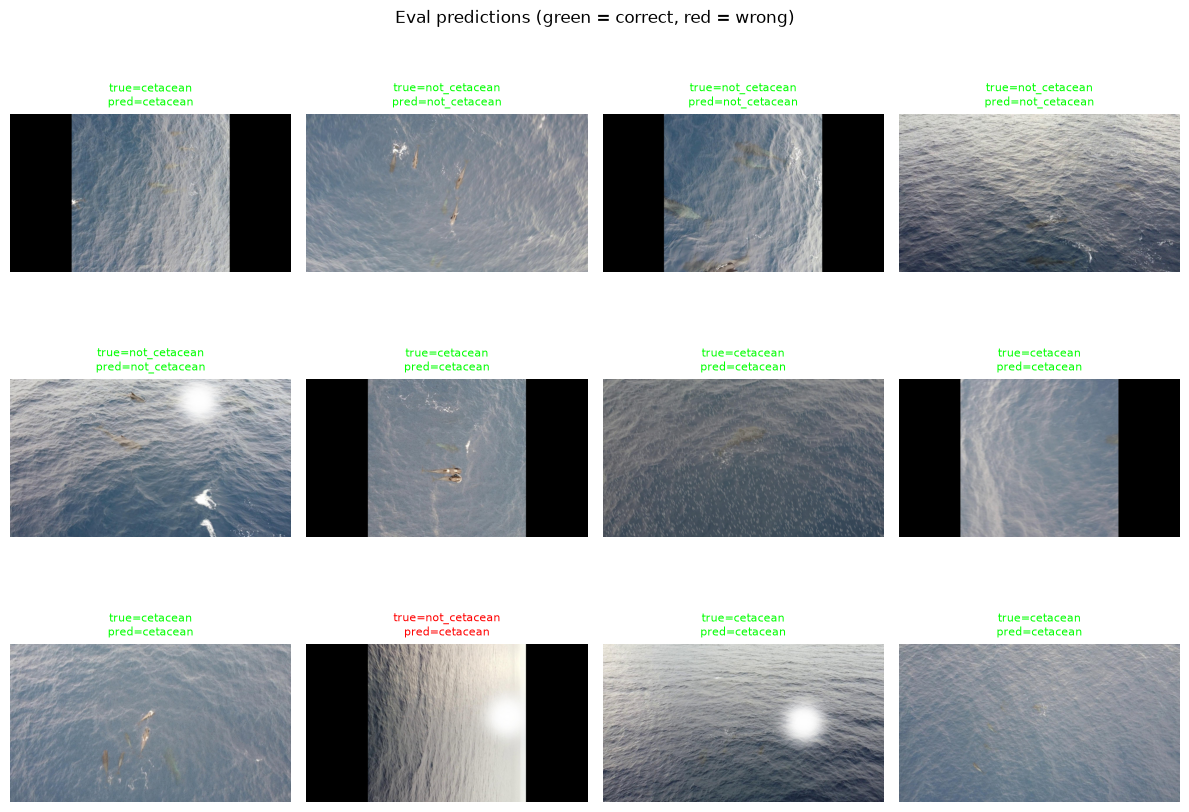

In [18]:
# --- Cell 10: Visual sample of eval predictions ---

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

N_SHOW = 12
_cet_eval = [r for r in eval_rows if r['kind'] in ('cet_annotation', 'water_patch')]   # v8: rows that come from cetacean photos
sample_rows = random.sample(_cet_eval, min(N_SHOW, len(_cet_eval)))
n_cols = 4
n_rows = (len(sample_rows) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 3, n_rows * 3))
axes = axes.flatten() if n_rows * n_cols > 1 else [axes]

for ax, row in zip(axes, sample_rows):
    img_path = next(r["path"] for r in records if r["path"].name == row["filename"])
    img = Image.open(img_path).convert("RGB")
    ax.imshow(img)
    x = np.array([[row[c] for c in cols]], dtype=float)
    pred = final_model.predict(x)[0]
    color = "lime" if pred == row["label"] else "red"
    ax.set_title(f"true={row["label"]}\npred={pred}", fontsize=8, color=color)
    ax.axis("off")
for ax in axes[len(sample_rows):]:
    ax.axis("off")

plt.suptitle("Eval predictions (green = correct, red = wrong)")
plt.tight_layout()
plt.show()

In [19]:
# --- Cell 11: Group-level accuracy - one vote per independent photo, not per row ---

from collections import defaultdict

by_group_label = defaultdict(list)
for row, pred in zip(eval_rows, y_pred):
    by_group_label[(row["group_id"], row["label"])].append(pred == row["label"])

group_majority_correct = {
    key: (sum(correct_list) / len(correct_list)) >= 0.5
    for key, correct_list in by_group_label.items()
}

print("Group-level accuracy (each independent photo counts once, however many duplicate copies it has):\n")
all_correct, all_total = 0, 0
for label in LABELS:
    keys = [k for k in group_majority_correct if k[1] == label]
    n_correct = sum(group_majority_correct[k] for k in keys)
    all_correct += n_correct
    all_total += len(keys)
    print(f"  {label:<14} {n_correct:>4} / {len(keys):<4} groups correct  ({n_correct / len(keys):.1%})")

print(f"\n  overall        {all_correct:>4} / {all_total:<4} groups correct  ({all_correct / all_total:.1%})")
print(f"\nCompare to row-level accuracy from cell 9: {(y_pred == y_eval).mean():.1%} (across {len(y_eval)} rows)")

n_multi_copy_groups = sum(1 for label in LABELS for k in by_group_label if k[1] == label and len(by_group_label[k]) > 1)
print(f"\n{n_multi_copy_groups} (group, label) combinations in eval had more than one row "
      f"(duplicate copies or multiple boxes) - these no longer get extra weight in the score above.")

Group-level accuracy (each independent photo counts once, however many duplicate copies it has):

  cetacean        206 / 238  groups correct  (86.6%)
  not_cetacean    600 / 639  groups correct  (93.9%)

  overall         806 / 877  groups correct  (91.9%)

Compare to row-level accuracy from cell 9: 82.9% (across 7150 rows)

837 (group, label) combinations in eval had more than one row (duplicate copies or multiple boxes) - these no longer get extra weight in the score above.
